In [120]:

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

df = pd.read_excel("fraud_detection.xlsx")

print("INSUREAI DATASET")
print("================")
print("Shape:", df.shape)
print("\nColumns:", len(df.columns))
print("\nFraud distribution:")
print(df["fraud_reported"].value_counts())

display(df.head())


INSUREAI DATASET
Shape: (1000, 39)

Columns: 39

Fraud distribution:
fraud_reported
N    753
Y    247
Name: count, dtype: int64


,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,...,witnesses,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,auto_year,fraud_reported
0,328,48,521585,2014-10-17,OH,250/500,1000,1406.91,0,466132,...,2,YES,71610,6510,13020,52080,Saab,92x,2004,Y
1,228,42,342868,2006-06-27,IN,250/500,2000,1197.22,5000000,468176,...,0,?,5070,780,780,3510,Mercedes,E400,2007,Y
2,134,29,687698,2000-09-06,OH,100/300,2000,1413.14,5000000,430632,...,3,NO,34650,7700,3850,23100,Dodge,RAM,2007,N
3,256,41,227811,1990-05-25,IL,250/500,2000,1415.74,6000000,608117,...,2,NO,63400,6340,6340,50720,Chevrolet,Tahoe,2014,Y
4,228,44,367455,2014-06-06,IL,500/1000,1000,1583.91,6000000,610706,...,1,NO,6500,1300,650,4550,Accura,RSX,2009,N


In [121]:

remove_columns = [
    "policy_number",
    "policy_bind_date",
    "incident_date",
    "claim_complexity"
]

X_fraud = df.drop(
    columns=["fraud_reported"] + remove_columns,
    errors="ignore"
).copy()

y_fraud = df["fraud_reported"].copy()

# Preserve missing values while normalizing categorical data
categorical_fraud = X_fraud.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

for col in categorical_fraud:
    X_fraud[col] = X_fraud[col].map(
        lambda value: str(value) if pd.notna(value) else np.nan
    )

numeric_fraud = X_fraud.select_dtypes(
    include=["number"]
).columns.tolist()

print("FRAUD MODEL INPUT")
print("=================")
print("Features:", X_fraud.shape[1])
print("Numerical:", len(numeric_fraud))
print("Categorical:", len(categorical_fraud))
print("\nTarget classes:")
print(y_fraud.value_counts())


FRAUD MODEL INPUT
Features: 35
Numerical: 17
Categorical: 18

Target classes:
fraud_reported
N    753
Y    247
Name: count, dtype: int64


In [122]:

indices = np.arange(len(df))

# First reserve 20% for final testing
trainval_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=y_fraud
)

# Split remaining 80% into 60% training and 20% validation
train_idx, val_idx = train_test_split(
    trainval_idx,
    test_size=0.25,
    random_state=42,
    stratify=y_fraud.iloc[trainval_idx]
)

print("DATA SPLIT")
print("==========")
print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))


DATA SPLIT
Training: 600
Validation: 200
Testing: 200


In [123]:

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

fraud_preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_fraud),
    ("cat", categorical_transformer, categorical_fraud)
])

print("Fraud preprocessing pipeline created.")


Fraud preprocessing pipeline created.


In [124]:

X_train_fraud = X_fraud.iloc[train_idx]
X_val_fraud = X_fraud.iloc[val_idx]
X_test_fraud = X_fraud.iloc[test_idx]

y_train_fraud = y_fraud.iloc[train_idx]
y_val_fraud = y_fraud.iloc[val_idx]
y_test_fraud = y_fraud.iloc[test_idx]

fraud_model = Pipeline([
    ("preprocessor", fraud_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight={"N": 1, "Y": 3},
        n_jobs=-1
    ))
])

fraud_model.fit(X_train_fraud, y_train_fraud)

print("Improved fraud model trained.")


Improved fraud model trained.


In [125]:

fraud_class_index = list(fraud_model.classes_).index("Y")

val_probabilities = fraud_model.predict_proba(
    X_val_fraud
)[:, fraud_class_index]

thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

threshold_results = []

for threshold in thresholds:

    predictions = np.where(
        val_probabilities >= threshold,
        "Y",
        "N"
    )

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val_fraud, predictions),
        "Precision": precision_score(
            y_val_fraud, predictions,
            pos_label="Y", zero_division=0
        ),
        "Recall": recall_score(
            y_val_fraud, predictions,
            pos_label="Y", zero_division=0
        ),
        "F1": f1_score(
            y_val_fraud, predictions,
            pos_label="Y", zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))

best_threshold = float(
    threshold_df.sort_values(
        ["F1", "Precision"],
        ascending=False
    ).iloc[0]["Threshold"]
)

print("Selected fraud threshold:", best_threshold)


,Threshold,Accuracy,Precision,Recall,F1
0,0.20,0.745,0.490,0.959,0.648
1,0.25,0.820,0.592,0.857,0.700
2,0.30,0.845,0.667,0.735,0.699
3,0.35,0.830,0.667,0.612,0.638
4,0.40,0.805,0.667,0.408,0.506
5,0.45,0.800,0.800,0.245,0.375
6,0.50,0.750,0.400,0.041,0.074


Selected fraud threshold: 0.25


In [126]:

test_probabilities = fraud_model.predict_proba(
    X_test_fraud
)[:, fraud_class_index]

test_fraud_predictions = np.where(
    test_probabilities >= best_threshold,
    "Y",
    "N"
)

print("FINAL FRAUD MODEL EVALUATION")
print("============================")

print(
    "Accuracy:",
    round(accuracy_score(y_test_fraud, test_fraud_predictions), 4)
)

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test_fraud,
    test_fraud_predictions,
    labels=["N", "Y"],
    target_names=["Not Fraud", "Fraud"],
    zero_division=0
))

print("\nCONFUSION MATRIX")

fraud_cm = confusion_matrix(
    y_test_fraud,
    test_fraud_predictions,
    labels=["N", "Y"]
)

print(fraud_cm)


FINAL FRAUD MODEL EVALUATION
Accuracy: 0.8

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Not Fraud       0.95      0.77      0.85       151
       Fraud       0.56      0.88      0.68        49

    accuracy                           0.80       200
   macro avg       0.75      0.83      0.77       200
weighted avg       0.85      0.80      0.81       200


CONFUSION MATRIX
[[117  34]
 [  6  43]]


In [127]:

backend_dir = "backend"
os.makedirs(backend_dir, exist_ok=True)

X_fraud_trainval = X_fraud.iloc[trainval_idx]
y_fraud_trainval = y_fraud.iloc[trainval_idx]

final_fraud_model = clone(fraud_model)
final_fraud_model.fit(
    X_fraud_trainval,
    y_fraud_trainval
)

joblib.dump(
    final_fraud_model,
    os.path.join(backend_dir, "fraud_model_improved.pkl")
)

with open(
    os.path.join(backend_dir, "fraud_threshold.txt"),
    "w"
) as file:
    file.write(str(best_threshold))

print("FINAL FRAUD MODEL SAVED")
print("File: backend/fraud_model_improved.pkl")
print("Threshold:", best_threshold)
print("Training records:", len(trainval_idx))

FINAL FRAUD MODEL SAVED
File: backend/fraud_model_improved.pkl
Threshold: 0.25
Training records: 800


In [128]:

cost_remove_columns = [
    "fraud_reported",
    "total_claim_amount",
    "policy_number",
    "policy_bind_date",
    "incident_date",
    "claim_complexity",
    "injury_claim",
    "property_claim",
    "vehicle_claim",
    "collision_type"
]

X_cost = df.drop(
    columns=cost_remove_columns,
    errors="ignore"
).copy()

y_cost = df["total_claim_amount"].copy()

cost_categorical = X_cost.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

for col in cost_categorical:
    X_cost[col] = X_cost[col].map(
        lambda value: str(value) if pd.notna(value) else np.nan
    )

cost_numeric = X_cost.select_dtypes(
    include=["number"]
).columns.tolist()

print("COST MODEL FEATURES")
print("===================")
print("Feature count:", X_cost.shape[1])
print("Numerical:", len(cost_numeric))
print("Categorical:", len(cost_categorical))
print("\nTarget statistics:")
print(y_cost.describe())

COST MODEL FEATURES
Feature count: 30
Numerical: 13
Categorical: 17

Target statistics:
count      1000.00000
mean      52761.94000
std       26401.53319
min         100.00000
25%       41812.50000
50%       58055.00000
75%       70592.50000
max      114920.00000
Name: total_claim_amount, dtype: float64


In [129]:

X_train_cost = X_cost.iloc[trainval_idx]
X_test_cost = X_cost.iloc[test_idx]

y_train_cost = y_cost.iloc[trainval_idx]
y_test_cost = y_cost.iloc[test_idx]

cost_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ]), cost_numeric),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cost_categorical)
])

print("Cost preprocessing created.")
print("Training records:", len(X_train_cost))
print("Testing records:", len(X_test_cost))

Cost preprocessing created.
Training records: 800
Testing records: 200


In [130]:

low_types = ["Vehicle Theft", "Parked Car"]

collision_types = [
    "Single Vehicle Collision",
    "Multi-vehicle Collision"
]

def create_segment_model():

    return TransformedTargetRegressor(
        regressor=Pipeline([
            ("preprocessor", clone(cost_preprocessor)),
            ("regressor", RandomForestRegressor(
                n_estimators=500,
                max_depth=15,
                min_samples_split=5,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            ))
        ]),
        func=np.log1p,
        inverse_func=np.expm1
    )

train_types = X_train_cost["incident_type"]

low_mask = train_types.isin(low_types)
collision_mask = train_types.isin(collision_types)

low_cost_model = create_segment_model()
collision_cost_model = create_segment_model()

low_cost_model.fit(
    X_train_cost.loc[low_mask],
    y_train_cost.loc[low_mask]
)

collision_cost_model.fit(
    X_train_cost.loc[collision_mask],
    y_train_cost.loc[collision_mask]
)

print("Both segmented cost models trained.")
print("Low-cost training records:", int(low_mask.sum()))
print("Collision training records:", int(collision_mask.sum()))

Both segmented cost models trained.
Low-cost training records: 152
Collision training records: 648


In [131]:

def predict_segmented_cost(X_input, low_model, collision_model):

    predictions = np.full(len(X_input), np.nan, dtype=float)

    incident_types = X_input["incident_type"]

    low_positions = np.flatnonzero(
        incident_types.isin(low_types).to_numpy()
    )

    collision_positions = np.flatnonzero(
        incident_types.isin(collision_types).to_numpy()
    )

    if len(low_positions):
        predictions[low_positions] = low_model.predict(
            X_input.iloc[low_positions]
        )

    if len(collision_positions):
        predictions[collision_positions] = collision_model.predict(
            X_input.iloc[collision_positions]
        )

    if np.isnan(predictions).any():
        unknown_types = incident_types[
            np.isnan(predictions)
        ].unique().tolist()

        raise ValueError(
            f"Unsupported incident types: {unknown_types}"
        )

    return np.maximum(predictions, 0)

cost_test_predictions = predict_segmented_cost(
    X_test_cost,
    low_cost_model,
    collision_cost_model
)

cost_mae = mean_absolute_error(
    y_test_cost,
    cost_test_predictions
)

cost_rmse = np.sqrt(
    mean_squared_error(y_test_cost, cost_test_predictions)
)

cost_r2 = r2_score(
    y_test_cost,
    cost_test_predictions
)

print("SEGMENTED COST MODEL EVALUATION")
print("================================")
print("MAE:", round(cost_mae, 2))
print("RMSE:", round(cost_rmse, 2))
print("R2:", round(cost_r2, 4))

cost_comparison = pd.DataFrame({
    "Actual Cost": y_test_cost.values,
    "Predicted Cost": cost_test_predictions
})

display(cost_comparison.head(15).round(2))

SEGMENTED COST MODEL EVALUATION
MAE: 10252.55
RMSE: 13478.4
R2: 0.6678


,Actual Cost,Predicted Cost
0,5500,5105.16
1,49100,65153.29
2,54240,58341.19
3,53280,59027.96
4,81800,56946.21
5,67500,59288.59
6,70200,63031.41
7,71280,60578.59
8,34320,60908.34
9,55500,63778.29


In [132]:

all_low_mask = X_cost["incident_type"].isin(low_types)
all_collision_mask = X_cost["incident_type"].isin(collision_types)

final_low_cost_model = create_segment_model()
final_collision_cost_model = create_segment_model()

final_low_cost_model.fit(
    X_cost.loc[all_low_mask],
    y_cost.loc[all_low_mask]
)

final_collision_cost_model.fit(
    X_cost.loc[all_collision_mask],
    y_cost.loc[all_collision_mask]
)

joblib.dump(
    final_low_cost_model,
    os.path.join(backend_dir, "low_cost_model.pkl")
)

joblib.dump(
    final_collision_cost_model,
    os.path.join(backend_dir, "collision_cost_model.pkl")
)

print("FINAL SEGMENTED COST MODELS SAVED")
print("=================================")
print("backend/low_cost_model.pkl")
print("backend/collision_cost_model.pkl")
print("Low-cost records:", int(all_low_mask.sum()))
print("Collision records:", int(all_collision_mask.sum()))

FINAL SEGMENTED COST MODELS SAVED
backend/low_cost_model.pkl
backend/collision_cost_model.pkl
Low-cost records: 178
Collision records: 822


In [133]:

def calculate_complexity(row):

    score = 0

    severity = str(
        row.get("incident_severity", "")
    ).strip().lower()

    if severity in ["major damage", "total loss"]:
        score += 2
    elif severity == "minor damage":
        score += 1

    vehicles = pd.to_numeric(
        row.get("number_of_vehicles_involved", 0),
        errors="coerce"
    )
    vehicles = 0 if pd.isna(vehicles) else vehicles

    if vehicles >= 3:
        score += 2
    elif vehicles == 2:
        score += 1

    injuries = pd.to_numeric(
        row.get("bodily_injuries", 0),
        errors="coerce"
    )
    injuries = 0 if pd.isna(injuries) else injuries

    if injuries >= 2:
        score += 2
    elif injuries == 1:
        score += 1

    witnesses = pd.to_numeric(
        row.get("witnesses", 0),
        errors="coerce"
    )
    witnesses = 0 if pd.isna(witnesses) else witnesses

    if witnesses >= 2:
        score += 1

    police_report = str(
        row.get("police_report_available", "")
    ).strip().lower()

    if police_report in ["yes", "true"]:
        score += 1

    if score <= 2:
        return "Low"
    elif score <= 4:
        return "Medium"
    else:
        return "High"

# Illustrative Q-table-based action scores
actions = ["Approve", "Review", "Investigate"]

q_table = pd.DataFrame(
    [
        [10, 2, -5],
        [-2, 10, 5],
        [-10, 2, 10]
    ],
    index=["Low", "Medium", "High"],
    columns=actions,
    dtype=float
)

print("DECISION TABLE")
print("==============")
display(q_table)

q_table.to_csv(
    os.path.join(backend_dir, "rl_q_table.csv")
)

print("Q-table saved: backend/rl_q_table.csv")

DECISION TABLE


,Approve,Review,Investigate
Low,10.0,2.0,-5.0
Medium,-2.0,10.0,5.0
High,-10.0,2.0,10.0


Q-table saved: backend/rl_q_table.csv


In [134]:

def get_risk_state(probability):
    if probability >= best_threshold:
        return "High"
    return "Low"

def get_final_decision(risk_state, complexity):

    if risk_state == "High":
        return "Investigate"

    if complexity == "High":
        return "Review"

    return q_table.loc[risk_state].idxmax()

print("DECISION LOGIC TESTS")
print("====================")

test_cases = [
    (0.10, "Low"),
    (0.10, "High"),
    (0.60, "Low")
]

for probability, complexity in test_cases:

    risk = get_risk_state(probability)

    decision = get_final_decision(
        risk,
        complexity
    )

    print(
        f"Fraud probability: {probability:.2f} | "
        f"Risk: {risk} | "
        f"Complexity: {complexity} | "
        f"Decision: {decision}"
    )

DECISION LOGIC TESTS
Fraud probability: 0.10 | Risk: Low | Complexity: Low | Decision: Approve
Fraud probability: 0.10 | Risk: Low | Complexity: High | Decision: Review
Fraud probability: 0.60 | Risk: High | Complexity: Low | Decision: Investigate


In [135]:

# Use the final saved-model version for fraud probabilities
final_fraud_class_index = list(
    final_fraud_model.classes_
).index("Y")

fraud_test_probabilities = final_fraud_model.predict_proba(
    X_test_fraud
)[:, final_fraud_class_index]

# Cost predictions from the evaluation models
# These are from models trained on train + validation only.
cost_test_predictions = predict_segmented_cost(
    X_test_cost,
    low_cost_model,
    collision_cost_model
)

complexity_predictions = X_fraud.iloc[test_idx].apply(
    calculate_complexity,
    axis=1
)

risk_predictions = [
    get_risk_state(p)
    for p in fraud_test_probabilities
]

decision_predictions = [
    get_final_decision(risk, complexity)
    for risk, complexity in zip(
        risk_predictions,
        complexity_predictions
    )
]

final_results = pd.DataFrame({
    "Fraud_Probability": fraud_test_probabilities,
    "Expected_Cost": cost_test_predictions,
    "Claim_Complexity": complexity_predictions.values,
    "Risk_State": risk_predictions,
    "Final_Decision": decision_predictions
}, index=test_idx)

print("FINAL CLAIM ANALYSIS")
print("====================")
display(final_results.head(10))

print("\nDECISION SUMMARY")
print(final_results["Final_Decision"].value_counts())

FINAL CLAIM ANALYSIS


,Fraud_Probability,Expected_Cost,Claim_Complexity,Risk_State,Final_Decision
908,0.160,5105.156912,Low,Low,Approve
973,0.485,65153.294031,High,High,Investigate
154,0.155,58341.194200,High,Low,Review
977,0.475,59027.960962,High,High,Investigate
50,0.235,56946.213444,High,Low,Review
997,0.190,59288.592450,High,Low,Review
710,0.415,63031.407934,Medium,High,Investigate
166,0.500,60578.585826,High,High,Investigate
212,0.145,60908.336743,High,Low,Review
192,0.150,63778.290075,Medium,Low,Approve



DECISION SUMMARY
Final_Decision
Approve        83
Investigate    70
Review         47
Name: count, dtype: int64


In [136]:

def insurance_claim_system(claim_data):

    if isinstance(claim_data, dict):
        claim_data = pd.DataFrame([claim_data])

    # Align incoming columns with each model's required inputs
    fraud_input = claim_data.reindex(
        columns=X_fraud.columns
    )

    cost_input = claim_data.reindex(
        columns=X_cost.columns
    )

    # Fraud prediction
    fraud_index = list(
        final_fraud_model.classes_
    ).index("Y")

    fraud_probability = final_fraud_model.predict_proba(
        fraud_input
    )[0, fraud_index]

    # Cost prediction
    incident_type = str(
        cost_input.iloc[0]["incident_type"]
    )

    if incident_type in low_types:
        expected_cost = final_low_cost_model.predict(
            cost_input
        )[0]

    elif incident_type in collision_types:
        expected_cost = final_collision_cost_model.predict(
            cost_input
        )[0]

    else:
        raise ValueError(
            "Unsupported incident type: " + incident_type
        )

    # Complexity and decision
    complexity = calculate_complexity(
        claim_data.iloc[0]
    )

    risk_state = get_risk_state(
        fraud_probability
    )

    decision = get_final_decision(
        risk_state,
        complexity
    )

    return {
        "Fraud Probability": round(
            float(fraud_probability) * 100, 2
        ),
        "Expected Cost": round(
            max(0, float(expected_cost)), 2
        ),
        "Claim Complexity": complexity,
        "Risk State": risk_state,
        "Final Decision": decision
    }

sample_claim = X_fraud.iloc[[0]].copy()

sample_result = insurance_claim_system(
    sample_claim
)

print("SAMPLE CLAIM RESULT")
print("===================")

for key, value in sample_result.items():
    print(f"{key}: {value}")

SAMPLE CLAIM RESULT
Fraud Probability: 81.5
Expected Cost: 66689.49
Claim Complexity: High
Risk State: High
Final Decision: Investigate


Predictions saved: insurance_claim_predictions.csv


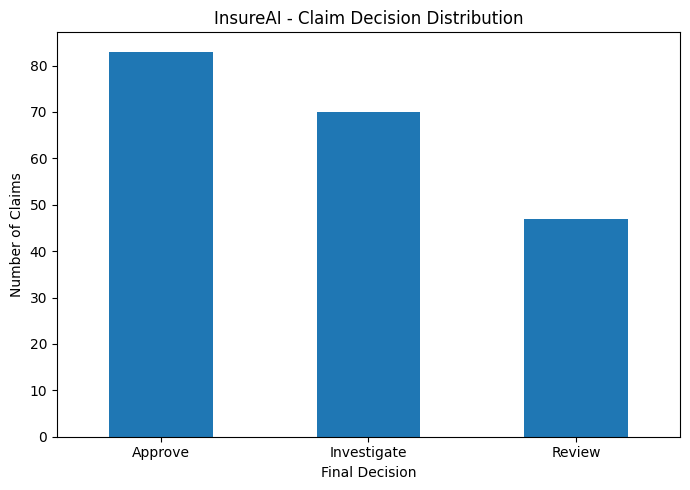

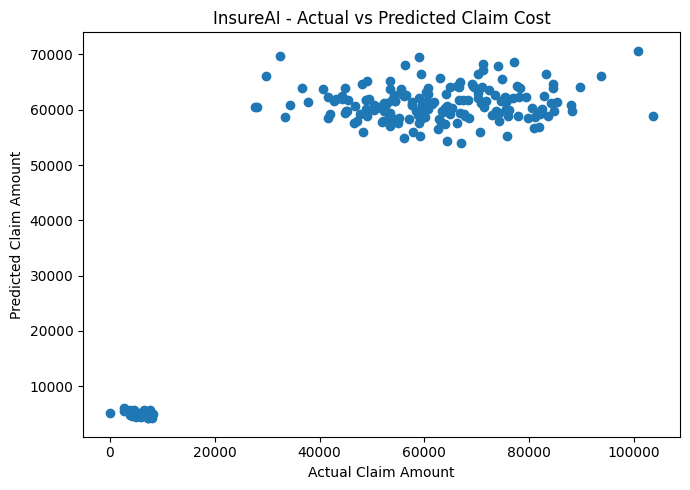

In [137]:

final_results.to_csv(
    "insurance_claim_predictions.csv",
    index=True
)

print("Predictions saved: insurance_claim_predictions.csv")

# Decision distribution
plt.figure(figsize=(7, 5))

final_results["Final_Decision"].value_counts().plot(
    kind="bar"
)

plt.title("InsureAI - Claim Decision Distribution")
plt.xlabel("Final Decision")
plt.ylabel("Number of Claims")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Actual vs predicted cost
plt.figure(figsize=(7, 5))

plt.scatter(
    y_test_cost,
    cost_test_predictions
)

plt.xlabel("Actual Claim Amount")
plt.ylabel("Predicted Claim Amount")
plt.title("InsureAI - Actual vs Predicted Claim Cost")
plt.tight_layout()
plt.show()

In [138]:

print("========================================")
print("          INSUREAI FINAL SUMMARY")
print("========================================")

print("\nDATASET")
print("Records:", len(df))
print("Original features:", df.shape[1])

print("\nFRAUD MODEL")
print("Model:", type(final_fraud_model).__name__)
print("Selected threshold:", best_threshold)
print("Test accuracy:", round(
    accuracy_score(y_test_fraud, test_fraud_predictions), 4
))

print("\nCOST MODELS")
print("Low-cost model:", type(final_low_cost_model).__name__)
print("Collision model:", type(final_collision_cost_model).__name__)
print("Test MAE:", round(cost_mae, 2))
print("Test RMSE:", round(cost_rmse, 2))
print("Test R2:", round(cost_r2, 4))

print("\nDECISION AGENT")
print("States:", q_table.index.tolist())
print("Actions:", q_table.columns.tolist())

print("\nSAVED FILES")
files_to_check = [
    "fraud_model_improved.pkl",
    "fraud_threshold.txt",
    "low_cost_model.pkl",
    "collision_cost_model.pkl",
    "rl_q_table.csv"
]

for filename in files_to_check:
    path = os.path.join(backend_dir, filename)
    print(filename, "→", os.path.exists(path))

print("\n========================================")
print("       INSUREAI NOTEBOOK COMPLETE")
print("========================================")

          INSUREAI FINAL SUMMARY

DATASET
Records: 1000
Original features: 39

FRAUD MODEL
Model: Pipeline
Selected threshold: 0.25
Test accuracy: 0.8

COST MODELS
Low-cost model: TransformedTargetRegressor
Collision model: TransformedTargetRegressor
Test MAE: 10252.55
Test RMSE: 13478.4
Test R2: 0.6678

DECISION AGENT
States: ['Low', 'Medium', 'High']
Actions: ['Approve', 'Review', 'Investigate']

SAVED FILES
fraud_model_improved.pkl → True
fraud_threshold.txt → True
low_cost_model.pkl → True
collision_cost_model.pkl → True
rl_q_table.csv → True

       INSUREAI NOTEBOOK COMPLETE
